# COU 07506 Digital Signal Processing: Week 01:
# Lab 0 Setting Up the DSP Laboratory

Name: BAKARI JUMA ABDURABI<br>
Registration Number:240242477743<br>
Class: BEng24COE<br>
Group: 14 (Stream 2)<br>
Date: 25 November 2026<br>
Environment: Google Colab <br>
Unit 1: Introduction to DSP and its role in AI  Module outcomes: LO1, LO8


## Pre-lab
**Pre-lab question: three devices I used today that contain DSP, and one signal each processes.**

**1. Computer (laptop)**
The signal my laptop processes is the audio from its microphone and to its speakers. The sound card's ADC and DAC, together with the audio codec, sample, filter and compress this audio. The laptop also processes Wi-Fi radio signals to keep its network connection.

**2. Mobile phone**
The signal my phone processes is my speech during a voice call. The phone samples my voice, removes background noise and echo, and compresses it with a speech codec. It then sends the compressed signal over the cellular radio link.

**3. Headphones**
The signal my headphones process is the music or audio played to my ears. They decode the digital audio stream (for example, over Bluetooth), apply equalisation and volume control, and drive the speaker. Noise-cancelling models also filter out the outside noise that their microphones pick up.

## Standard imports (from the Introduction)


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

import sys, scipy, matplotlib
print("Python    :", sys.version.split()[0])
print("NumPy     :", np.__version__)
print("SciPy     :", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)


Python    : 3.13.18
NumPy     : 2.4.6
SciPy     : 1.16.3
Matplotlib: 3.10.0


**Task 1.1: Your first notebook: elementary sequences**

A discrete time signal x(n) exists only at integer n, so it is stored as two arrays (the index n and the values x) and drawn with a stem plot. Here n runs from -5 to 10:

* unit impulse delta(n) = 1 for n=0, otherwise 0
* unit step u(n) = 1 for n \ge 0, otherwise 0
* unit ramp r(n) = n\,u(n)
* real exponential (0.8)^n u(n)


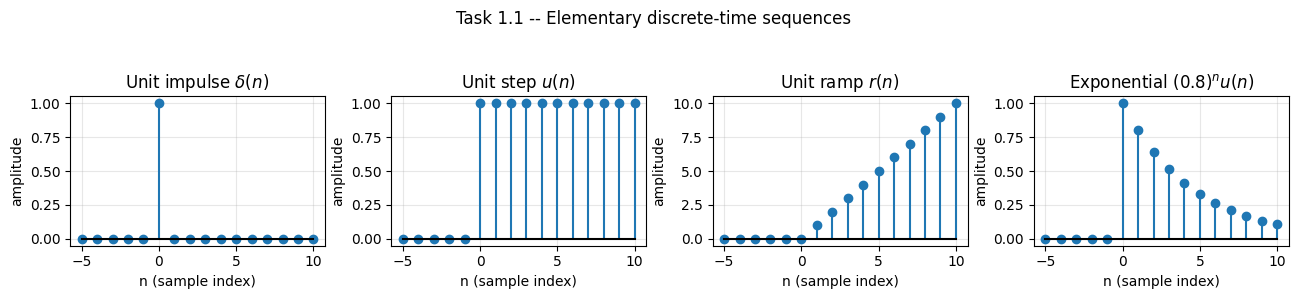

Checks passed: delta(0)=1, u(-1)=0, u(0)=1, r(10)=10, (0.8)^2 = 0.64


In [ ]:
n = np.arange(-5, 11)                 # n = -5, -4, ..., 10
delta = (n == 0).astype(float)        # unit impulse
step  = (n >= 0).astype(float)        # unit step
ramp  = n * step                      # unit ramp
expo  = 0.8**n * step                 # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.8))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        [r"Unit impulse $\delta(n)$", r"Unit step $u(n)$",
                         r"Unit ramp $r(n)$", r"Exponential $(0.8)^n u(n)$"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n (sample index)")
    ax.set_ylabel("amplitude")
    ax.grid(alpha=0.3)
fig.suptitle("Task 1.1 -- Elementary discrete-time sequences", y=1.05)
plt.tight_layout(); plt.show()

# Check a few values against the definitions
assert delta[n == 0][0] == 1 and delta.sum() == 1
assert step[n == -1][0] == 0 and step[n == 0][0] == 1
assert ramp[n == 10][0] == 10
assert np.isclose(expo[n == 2][0], 0.64)
print("Checks passed: delta(0)=1, u(-1)=0, u(0)=1, r(10)=10, (0.8)^2 = 0.64")


## Task 1.2:  Change the parameters

### Task 1.2.1: $a^n u(n)$ for $a = 0.5$, $a = -0.8$ and $a = 1.1$


a =   0.5:  x(0) = 1.000,  x(5) = 0.0312,  x(20) = 0.0000
a =  -0.8:  x(0) = 1.000,  x(5) = -0.3277,  x(20) = 0.0115
a =   1.1:  x(0) = 1.000,  x(5) = 1.6105,  x(20) = 6.7275


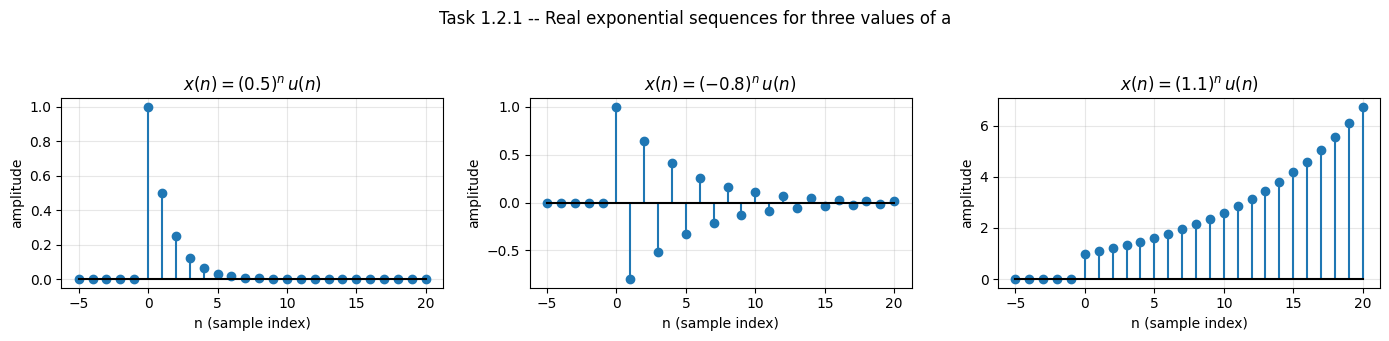

In [ ]:
n = np.arange(-5, 21)
u = (n >= 0).astype(float)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    x = (a ** n.astype(float)) * u
    ax.stem(n, x, basefmt="k-")
    ax.set_title(rf"$x(n) = ({a})^n\,u(n)$")
    ax.set_xlabel("n (sample index)")
    ax.set_ylabel("amplitude")
    ax.grid(alpha=0.3)
    print(f"a = {a:5}:  x(0) = {x[n==0][0]:.3f},  x(5) = {x[n==5][0]:.4f},  x(20) = {x[n==20][0]:.4f}")
fig.suptitle("Task 1.2.1 -- Real exponential sequences for three values of a", y=1.05)
plt.tight_layout(); plt.show()


**Observations.**
* $a = 0.5$ ($0 < a < 1$): the sequence decays towards zero. Each sample is half of the one before it.
* $a = -0.8$ ($-1 < a < 0$): the magnitude decays as $0.8^n$ and the sign alternates on every sample. This is the fastest possible oscillation, with frequency $\omega = \pi$.
* $a = 1.1$ ($|a| > 1$): the sequence grows without bound, reaching $1.1^{20} \approx 6.73$ at $n = 20$.


### Task 1.2.2: $\cos(2\pi n/8)$ and $\cos(2\pi n/7.5)$ for $0 \le n \le 40$


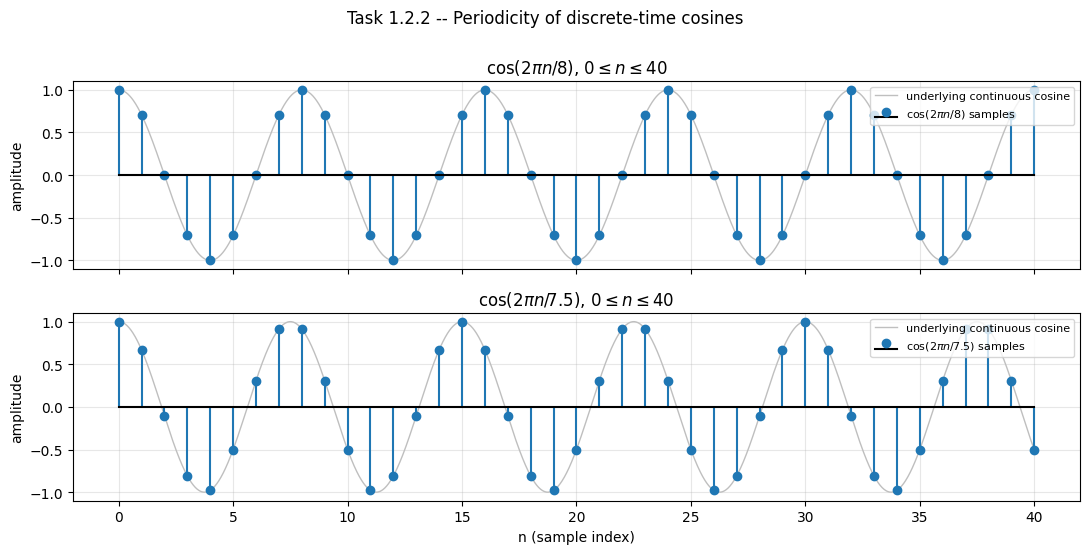

Does cos(2*pi*n/8)   repeat after 8 samples?   True
Does cos(2*pi*n/7.5) repeat after 8 samples?   False
Does cos(2*pi*n/7.5) repeat after 7 samples?   False
Fundamental period of cos(2*pi*n/8)  : 8 samples
Fundamental period of cos(2*pi*n/7.5): 15 samples


In [ ]:
n = np.arange(0, 41)
x1 = np.cos(2*np.pi*n/8)
x2 = np.cos(2*np.pi*n/7.5)
t = np.linspace(0, 40, 2000)         

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
for ax, x, P, lbl in [(axes[0], x1, 8, r"$\cos(2\pi n/8)$"),
                      (axes[1], x2, 7.5, r"$\cos(2\pi n/7.5)$")]:
    ax.plot(t, np.cos(2*np.pi*t/P), color="0.75", lw=1, label="underlying continuous cosine")
    ax.stem(n, x, basefmt="k-", label=lbl + " samples")
    ax.set_ylabel("amplitude")
    ax.set_title(lbl + rf", $0 \leq n \leq 40$")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(alpha=0.3)
axes[1].set_xlabel("n (sample index)")
fig.suptitle("Task 1.2.2 -- Periodicity of discrete-time cosines", y=1.0)
plt.tight_layout(); plt.show()

def fundamental_period(x, max_N=40, tol=1e-9):
    """Smallest integer N with x(n+N) = x(n) for every sample available."""
    for N in range(1, max_N):
        if np.allclose(x[N:], x[:-N], atol=tol):
            return N
    return None

print("Does cos(2*pi*n/8)   repeat after 8 samples?  ", np.allclose(x1[8:], x1[:-8]))
print("Does cos(2*pi*n/7.5) repeat after 8 samples?  ", np.allclose(x2[8:], x2[:-8]))
print("Does cos(2*pi*n/7.5) repeat after 7 samples?  ", np.allclose(x2[7:], x2[:-7]))
print("Fundamental period of cos(2*pi*n/8)  :", fundamental_period(x1), "samples")
print("Fundamental period of cos(2*pi*n/7.5):", fundamental_period(x2), "samples")


**Which one repeats exactly?**
$\cos(2\pi n/8)$ repeats exactly every **8 samples**. Each cycle has the same 8 values, and the samples land on the same points of the cosine in every cycle.

$\cos(2\pi n/7.5)$ does **not** repeat after one cycle of the underlying cosine, because one cycle is 7.5 samples long and a discrete-time signal can only repeat after a whole number of samples. In the plot, the samples land on different points of the cosine in each cycle.

A discrete-time sinusoid $\cos(2\pi f_0 n)$ is periodic only when $f_0$ is a ratio of integers $k/N$, and its period is then $N$ (with $k/N$ in lowest terms). Here $f_0 = 1/7.5 = 2/15$, so the sequence first repeats after **N = 15 samples**, which is two cycles of the cosine. The code above confirms this: the fundamental periods are 8 and 15 samples.


## Task 1.3: Working with audio

**Recording:** I recorded my voice on my phone (about 9 s; the manual asks for 3--5 s, and a slightly longer clip works the same way) and uploaded it to Colab with the **Files** panel (folder icon on the left).
My phone saved the recording in **M4A (AAC) format** inside an `.mp4` file, not as WAV, so the first cell converts it to a WAV file (`my_voice.wav`, 16-bit PCM, mono, at the phone's original sampling rate) with **ffmpeg**, which is pre-installed in Colab. The manual's code then reads the WAV file unchanged. So the notebook still runs from top to bottom.


In [ ]:
import os, glob, subprocess

# Convert the phone recording (M4A/AAC in an .mp4 container) to a 16-bit PCM mono WAV file.
# No resampling: the WAV keeps the phone's original sampling rate.
if not os.path.exists("my_voice.wav"):
    candidates = [f for f in glob.glob("*") if f.lower().endswith((".m4a", ".mp4", ".aac", ".3gp", ".ogg", ".mp3"))]
    if candidates:
        src = candidates[0]
        print("Converting:", src)
        subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", src,
                        "-ac", "1", "-c:a", "pcm_s16le", "my_voice.wav"], check=True)
    else:
        print("No phone recording found -- the fallback test signal will be used.")

if os.path.exists("my_voice.wav"):
    info = subprocess.run(["ffprobe", "-v", "error", "-show_entries",
                           "stream=codec_name,sample_rate,channels,duration",
                           "-of", "default=noprint_wrappers=1", "my_voice.wav"],
                          capture_output=True, text=True).stdout
    print("my_voice.wav ->\n" + info)


Converting: my_voice.m4a
my_voice.wav ->
codec_name=pcm_s16le
sample_rate=48000
channels=1
duration=8.938667



Raw data type from file: int16 | shape: (429056,)
Source: my voice recording
fs = 48000 Hz, duration = 8.94 s, samples = 429056


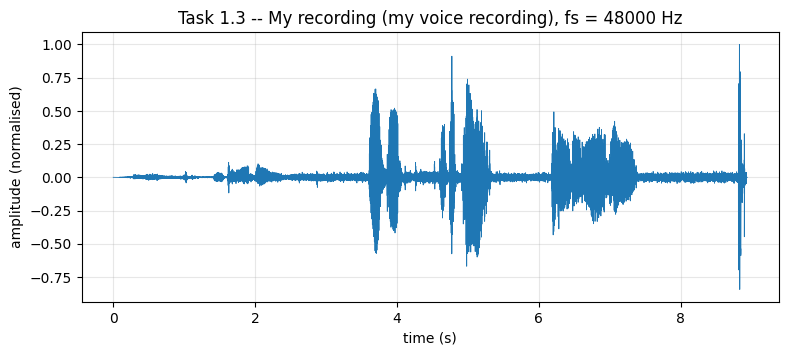

In [ ]:
import os
from IPython.display import Audio, display

fname = "my_voice.wav"                 # change to your file name

if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    print("Raw data type from file:", x.dtype, "| shape:", x.shape)
    x = x.astype(float)
    if x.ndim > 1:                     # stereo -> mono
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))          # normalise to [-1, 1]
    source = "my voice recording"
else:                                  # fallback test signal
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)
    source = "fallback test signal (440 Hz decaying sine)"

t = np.arange(len(x)) / fs
print(f"Source: {source}")
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")

plt.plot(t, x, lw=0.6)
plt.xlabel("time (s)"); plt.ylabel("amplitude (normalised)")
plt.title(f"Task 1.3 -- My recording ({source}), fs = {fs} Hz")
plt.grid(alpha=0.3); plt.show()

display(Audio(x, rate=fs))             # play back in the notebook


**Zoom in and check the frequency content.** Even though the full recording looks continuous, it is really a list of samples. Zooming in on a voiced part of the speech (the 50 ms frame with the highest energy, ignoring the first and last 0.5 s where the phone's button clicks are) shows 20 ms of the waveform, and a 2 ms stem plot inside it shows the individual samples, spaced $T_s = 1/f_s$ apart. The magnitude spectrum (FFT) then shows which frequencies carry the energy.


Loudest voiced frame starts at t = 4.982 s;  sampling period Ts = 1/fs = 20.83 microseconds


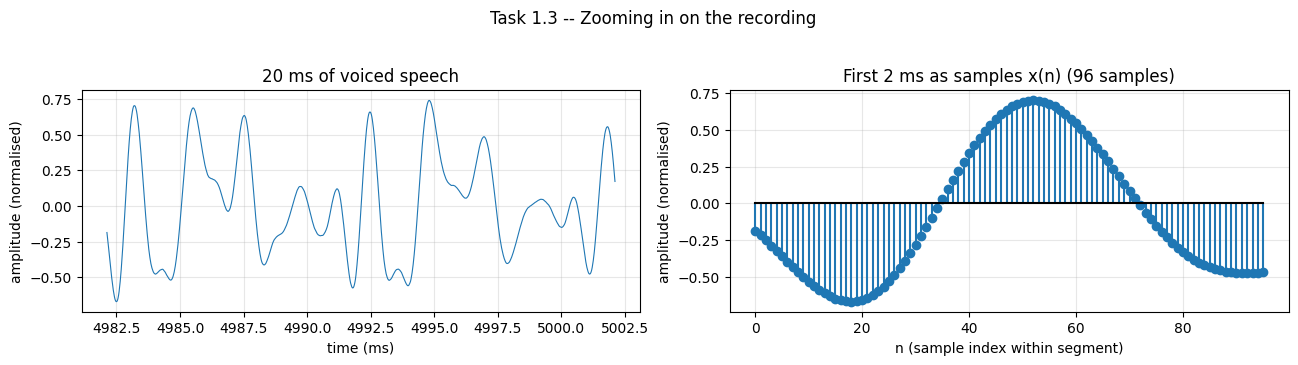

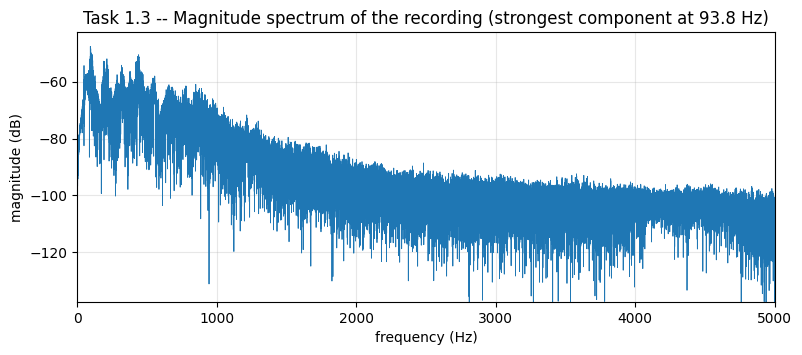

Strongest frequency component: 93.8 Hz


In [ ]:
# Find the 50 ms frame with the highest energy, away from the start/end clicks
frame = int(0.050*fs)
lo, hi = int(0.5*fs), max(len(x) - int(0.5*fs) - frame, int(0.5*fs) + 1)
if hi - lo < frame:                                  # very short signal: search everywhere
    lo, hi = 0, max(len(x) - frame, 1)
energy = np.convolve(x[lo:hi+frame]**2, np.ones(frame), mode="valid")
start = lo + int(np.argmax(energy))
print(f"Loudest voiced frame starts at t = {start/fs:.3f} s;  sampling period Ts = 1/fs = {1e6/fs:.2f} microseconds")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
seg20 = slice(start, start + int(0.020*fs))          # 20 ms
axes[0].plot(t[seg20]*1000, x[seg20], lw=0.8)
axes[0].set_title("20 ms of voiced speech")
axes[0].set_xlabel("time (ms)"); axes[0].set_ylabel("amplitude (normalised)"); axes[0].grid(alpha=0.3)
seg2 = slice(start, start + int(0.002*fs))           # 2 ms -> 96 samples at 48 kHz
axes[1].stem(np.arange(seg2.stop - seg2.start), x[seg2], basefmt="k-")
axes[1].set_title(f"First 2 ms as samples x(n) ({seg2.stop - seg2.start} samples)")
axes[1].set_xlabel("n (sample index within segment)"); axes[1].set_ylabel("amplitude (normalised)"); axes[1].grid(alpha=0.3)
fig.suptitle("Task 1.3 -- Zooming in on the recording", y=1.03)
plt.tight_layout(); plt.show()

# Magnitude spectrum of the whole recording
X = np.abs(np.fft.rfft(x)) / len(x)
f = np.fft.rfftfreq(len(x), d=1/fs)
k_peak = np.argmax(X[1:]) + 1
XdB = 20*np.log10(X + 1e-12)
plt.plot(f, XdB, lw=0.6)
plt.xlim(0, min(fs/2, 5000)); plt.ylim(XdB.max() - 90, XdB.max() + 5)
plt.xlabel("frequency (Hz)"); plt.ylabel("magnitude (dB)")
plt.title(f"Task 1.3 -- Magnitude spectrum of the recording (strongest component at {f[k_peak]:.1f} Hz)")
plt.grid(alpha=0.3); plt.show()
print(f"Strongest frequency component: {f[k_peak]:.1f} Hz")


**Spectrum.** Most of the energy of my voice is below about 1 kHz, and it falls off steadily at higher frequencies. The strongest component is close to 94 Hz, inside the normal range of adult voice pitch (roughly 85--255 Hz), and the smaller peaks above it are its harmonics, shaped by the resonances (formants) of my vocal tract. This also shows why telephone speech sampled at only 8 kHz is still understandable, while music recordings use 44.1 or 48 kHz to keep frequencies up to 20 kHz.


**Verification on a signal with a known answer.** As the manual asks, the same analysis is checked on the manual's fallback test signal (a 440 Hz sine with amplitude 0.5 and an exponential decay). The FFT peak must appear at 440 Hz.


In [ ]:
fs_test = 16000
t_test = np.arange(0, 2, 1/fs_test)
x_test = 0.5*np.sin(2*np.pi*440*t_test) * np.exp(-t_test)
X_test = np.abs(np.fft.rfft(x_test))
f_test = np.fft.rfftfreq(len(x_test), d=1/fs_test)
f_peak_test = f_test[np.argmax(X_test)]
print(f"Test signal: fs = {fs_test} Hz, duration = {len(x_test)/fs_test:.2f} s, samples = {len(x_test)}")
print(f"FFT peak of the test signal = {f_peak_test:.1f} Hz (expected 440 Hz)")
assert abs(f_peak_test - 440) <= fs_test/len(x_test), "peak is not at 440 Hz"
print("Check passed: the analysis finds the known frequency.")


Test signal: fs = 16000 Hz, duration = 2.00 s, samples = 32000
FFT peak of the test signal = 440.0 Hz (expected 440 Hz)
Check passed: the analysis finds the known frequency.


**Write the audio back to a file and read it again** (objective 3: read *and* write audio files). The normalised signal is saved as a 16-bit PCM WAV file, read back, and compared with the original.


In [1]:
out_name = "week01_processed.wav"
x_int16 = np.int16(np.round(x * 32767))          
wavfile.write(out_name, fs, x_int16)

fs_back, y = wavfile.read(out_name)
y = y / 32767
print(f"Wrote {out_name}: {os.path.getsize(out_name)} bytes")
print(f"Read back: fs = {fs_back} Hz, samples = {len(y)}, dtype in file = int16")
print(f"Max difference after 16-bit round trip = {np.max(np.abs(x - y)):.2e} (about half a 16-bit step, 1/65534 = 1.5e-05)")
display(Audio(y, rate=fs_back))


## Task 1.4: The same in Octave (optional)

Colab normally runs Python, but GNU Octave can be installed on the Colab virtual machine with `apt-get`. The script below repeats Task 1.1 in Octave, saves the figure as a PNG


In [ ]:
%%bash
if ! command -v octave >/dev/null 2>&1; then
  apt-get -qq update > /dev/null && apt-get -qq install -y octave gnuplot > /dev/null 2>&1
fi
octave --version | head -n 1

cat > task1_4.m <<'EOF'
% Task 1.4 -- elementary sequences in GNU Octave
warning("off", "all");
graphics_toolkit("gnuplot");
set(0, "defaultfigurevisible", "off");
n = -5:10;
delta = double(n == 0);          % unit impulse
step  = double(n >= 0);          % unit step
ramp  = n .* step;               % unit ramp
expo  = (0.8 .^ n) .* step;      % real exponential
figure("position", [0 0 1300 300]);
subplot(1,4,1); stem(n, delta, "filled"); xlim([-5.5 10.5]); title("unit impulse delta(n)"); xlabel("n (sample index)"); ylabel("amplitude");
subplot(1,4,2); stem(n, step,  "filled"); xlim([-5.5 10.5]); title("unit step u(n)"); xlabel("n (sample index)"); ylabel("amplitude");
subplot(1,4,3); stem(n, ramp,  "filled"); xlim([-5.5 10.5]); title("unit ramp r(n)"); xlabel("n (sample index)"); ylabel("amplitude");
subplot(1,4,4); stem(n, expo,  "filled"); xlim([-5.5 10.5]); title("(0.8)^n u(n)"); xlabel("n (sample index)"); ylabel("amplitude");
print("-dpng", "-r100", "task1_4_octave.png");
printf("n        = "); printf("%3d ", n);    printf("\n");
printf("u(n)     = "); printf("%3d ", step); printf("\n");
printf("r(n)     = "); printf("%3d ", ramp); printf("\n");
EOF
octave --no-gui -q task1_4.m 2>/dev/null
echo "Octave script finished; figure saved as task1_4_octave.png"


GNU Octave, version 8.4.0
n        =  -5  -4  -3  -2  -1   0   1   2   3   4   5   6   7   8   9  10 
u(n)     =   0   0   0   0   0   1   1   1   1   1   1   1   1   1   1   1 
r(n)     =   0   0   0   0   0   0   1   2   3   4   5   6   7   8   9  10 
Octave script finished; figure saved as task1_4_octave.png


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
octave: X11 DISPLAY environment variable not set
octave: disabling GUI features


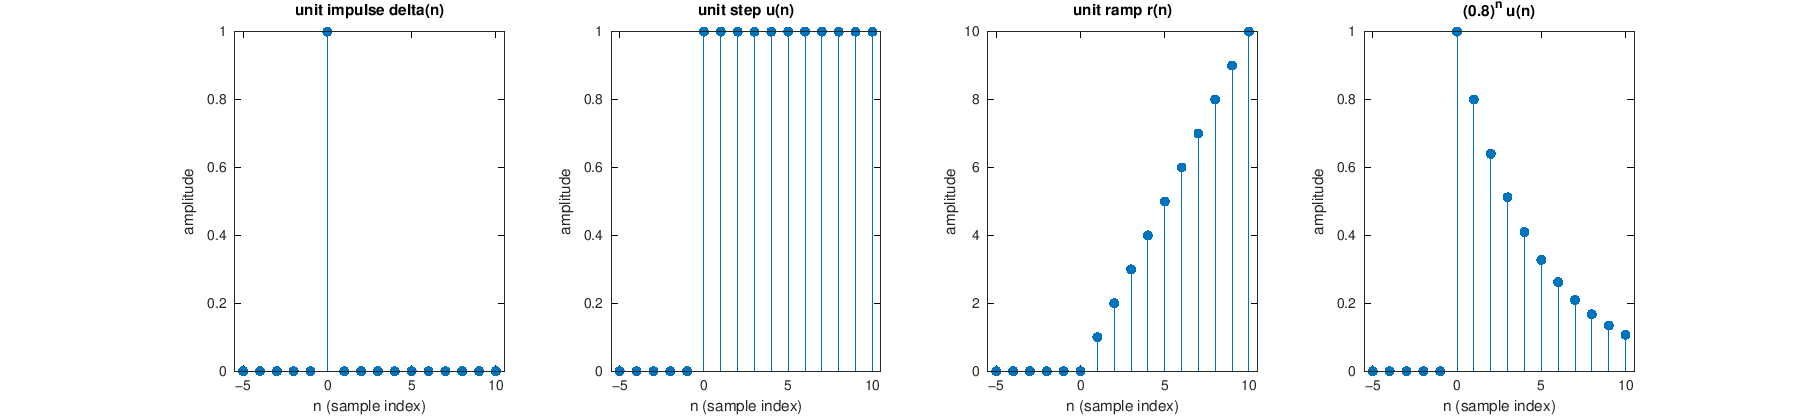

In [ ]:
from IPython.display import Image
if os.path.exists("task1_4_octave.png"):
    display(Image("task1_4_octave.png"))
else:
    print("Octave figure not produced -- see the output of the cell above.")


**Syntax differences between Python (NumPy) and Octave:**

| Operation | Python / NumPy | Octave / MATLAB |
|---|---|---|
| Index vector $-5 \dots 10$ | `np.arange(-5, 11)` (end value excluded) | `-5:10` (end value included) |
| Logical to number | `(n >= 0).astype(float)` | `double(n >= 0)` |
| Element-wise multiply / power | `*`, `**` | `.*`, `.^` |
| Array indexing | starts at 0, square brackets `x[0]` | starts at 1, round brackets `x(1)` |
| Stem plot | `plt.stem(n, x)` | `stem(n, x)` |
| Comments | `#` | `%` |
| Libraries | must be imported (`import numpy as np`) | built in; signal package loaded with `pkg load signal` |


## Analysis questions


**Q1. What is the sampling rate of your phone's recording? How many numbers are needed to store one minute of it in mono?**

My phone's recording has a sampling rate of **$f_s = 48\,000$ Hz (48 kHz)**, as printed in Task 1.3 and in the cell above. My recording of about 9 s therefore holds 429 056 samples. One minute of mono audio needs one number per sample:

$$N = f_s \times 60\ \text{s} = 48\,000 \times 60 = 2\,880\,000 \text{ numbers}$$

At 16 bits (2 bytes) per sample this is about 5.76 MB. A stereo recording needs twice as many numbers

**Q2. Why is a stem plot more appropriate than a continuous line for $x(n)$?**

A discrete-time signal is defined only at integer values of $n$. Between $n$ and $n+1$ it has no value at all, not even zero. A stem plot draws exactly one value at each integer index, so it shows the signal as it really is: a list of numbers. A continuous line joins the points and suggests that values exist between the samples, which is false. It can also be misleading: in Task 1.2.2 a joined line would hide the fact that $\cos(2\pi n/7.5)$ has a period of 15 samples, not 7.5.

**Q3. For $a = 1.1$ the exponential grows. Which property of a system would such a signal violate if it were an impulse response (Unit 1 §1.7)?**

It would violate **BIBO stability** (bounded-input, bounded-output). An LTI system is stable only if its impulse response is absolutely summable:

$$\sum_{n=-\infty}^{\infty} |h(n)| < \infty$$

For $h(n) = (1.1)^n u(n)$ the sum $\sum_{n=0}^{\infty} 1.1^n$ is a geometric series with ratio $1.1 > 1$, so it diverges. A bounded input such as a unit step would then give an output that grows without limit.

In [ ]:
# Numerical check for Q3: partial sums of |h(n)| for N = 10, 50, 100 terms
for a in [0.5, -0.8, 1.1]:
    partial = [np.sum(np.abs(a)**np.arange(N)) for N in (10, 50, 100)]
    limit = f"{1/(1-abs(a)):.1f}" if abs(a) < 1 else "infinity (diverges)"
    print(f"a = {a:5}: sum|h| for N=10, 50, 100 -> {partial[0]:.3f}, {partial[1]:.3f}, {partial[2]:.3e}   limit = {limit}")


a =   0.5: sum|h| for N=10, 50, 100 -> 1.998, 2.000, 2.000e+00   limit = 2.0
a =  -0.8: sum|h| for N=10, 50, 100 -> 4.463, 5.000, 5.000e+00   limit = 5.0
a =   1.1: sum|h| for N=10, 50, 100 -> 15.937, 1163.909, 1.378e+05   limit = infinity (diverges)
